<a href="https://colab.research.google.com/github/zakateryila/Zaka-Teryila-Peter-/blob/main/AI_Day15_CNN_CIFAR10_%3Czakateryila%3E_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Confirm GPU availability
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✅ Connected to GPU: {gpus[0].name}")
else:
    print("⚠️ Warning: Running on CPU. Switch via Runtime -> Change runtime type")

print(f"TensorFlow Version: {tf.__version__}")

✅ Connected to GPU: /physical_device:GPU:0
TensorFlow Version: 2.21.0


In [2]:
# Load the balanced 10-class benchmark dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Human-readable labels mapped to integer indices (0-9)
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

print("Train images shape:", x_train.shape)  # (50000, 32, 32, 3)
print("Train labels shape:", y_train.shape)   # (50000, 1)
print("Test images shape :", x_test.shape)    # (10000, 32, 32, 3)
print("Raw pixel range :", x_train.min(), "to", x_train.max())

Train images shape: (50000, 32, 32, 3)
Train labels shape: (50000, 1)
Test images shape : (10000, 32, 32, 3)
Raw pixel range : 0 to 255


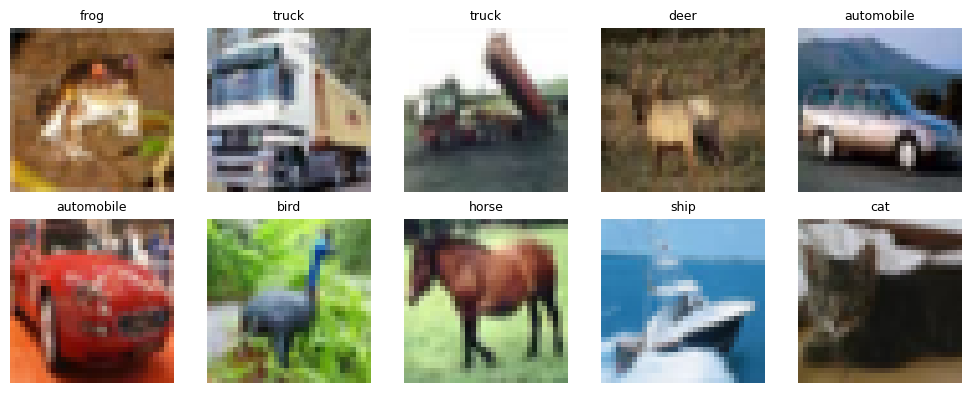

In [3]:
# Plot a 2x5 grid of training images with ground-truth labels
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[int(y_train[i][0])], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
st = x_test.astype("float32") / 255.0

In [5]:
# Build the CNN Architecture
model = tf.keras.models.Sequential([
    # Input layer and block 1
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Block 2: Conv + MaxPool
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Head: Flatten + Dense + Output
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [7]:
# Normalize training images to [0.0, 1.0]
x_train_norm = x_train.astype("float32") / 255.0

EPOCHS = 10
BATCH_SIZE = 64

history = model.fit(
    x_train_norm,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.1  # Reserves 5,000 images strictly for validation
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.4530 - loss: 1.5214 - val_accuracy: 0.5288 - val_loss: 1.3063
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5897 - loss: 1.1727 - val_accuracy: 0.5252 - val_loss: 1.3273
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6375 - loss: 1.0365 - val_accuracy: 0.6580 - val_loss: 0.9979
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6674 - loss: 0.9548 - val_accuracy: 0.6770 - val_loss: 0.9540
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6922 - loss: 0.8855 - val_accuracy: 0.6930 - val_loss: 0.9010
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7149 - loss: 0.8281 - val_accuracy: 0.6926 - val_loss: 0.9038
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7309 - loss: 0.7817 - val_accuracy: 0.7010 - val_loss: 0.8772
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7478 - loss: 0.7296 - val_accuracy: 

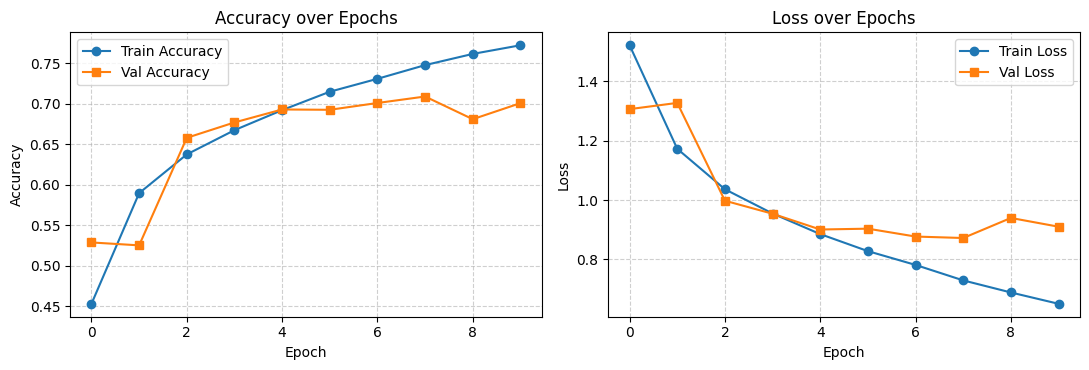

In [8]:
# Plot Learning Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

# Panel 1: Accuracy Curves
ax1.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
ax1.plot(history.history['val_accuracy'], label='Val Accuracy', marker='s')
ax1.set_title('Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# Panel 2: Cross-Entropy Loss Curves
ax2.plot(history.history['loss'], label='Train Loss', marker='o')
ax2.plot(history.history['val_loss'], label='Val Loss', marker='s')
ax2.set_title('Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [9]:
# Evaluate the model
test_loss, test_acc = model.evaluate(st, y_test, verbose=0)
print(f"Test Cross-Entropy Loss: {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f} ({test_acc*100:.2f}%)")

Test Cross-Entropy Loss: 0.9442
Test Accuracy : 0.6911 (69.11%)


In [10]:
sample_idx = 17
input_sample = st[sample_idx:sample_idx + 1]  # Keep batch dim: (1, 32, 32, 3)
probs = model.predict(input_sample, verbose=0)[0]
top_3 = np.argsort(probs)[-3:][::-1]

print(f"Actual: {class_names[int(y_test[sample_idx][0])]} | Top Prediction: {class_names[top_3[0]]} ({probs[top_3[0]]:.1%})")
for rank, idx in enumerate(top_3, 1):
    print(f" {rank}. {class_names[idx]:<11}: {probs[idx]:.2%}")

Actual: horse | Top Prediction: horse (56.9%)
 1. horse      : 56.90%
 2. cat        : 22.76%
 3. deer       : 5.98%


In [11]:
import os
from PIL import Image
import numpy as np

# Automatically create mock directory structure if it doesn't exist
mock_dir = "dataset/train"
subdirs = ["cat", "dog"]

if not os.path.exists(mock_dir):
    print(f"📁 Creating mock directories at: {mock_dir}")
    for subdir in subdirs:
        path = os.path.join(mock_dir, subdir)
        os.makedirs(path, exist_ok=True)

        # Create 2 placeholder images per class to allow the dataset loader to function
        for i in range(2):
            dummy_data = np.random.randint(0, 255, (32, 32, 3), dtype=np.uint8)
            img = Image.fromarray(dummy_data)
            img.save(os.path.join(path, f"mock_{i}.jpg"))
    print("✅ Mock dataset directories and images generated successfully!")

# Load the dataset from the directory structure
train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/train",
    labels="inferred",  # Assigns integer label based on subfolder name
    label_mode="int"     # Yields integer labels
)

Found 4 files belonging to 2 classes.


In [12]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset/train",
    labels="inferred",  # Assigns integer label based on subfolder name
    label_mode="int",    # Yields integer labels for sparse cross-entropy
    image_size=(32, 32), # Automatically resizes images
    batch_size=64,
    shuffle=True
)

Found 4 files belonging to 2 classes.


In [13]:
from tensorflow.keras.preprocessing import image
import numpy as np

def predict_image(image_path, model, class_names):
    # 1. Load image and resize to match model input shape
    img = image.load_img(image_path, target_size=(32, 32))

    # 2. Convert PIL image to float32 NumPy array and scale to [0, 1]
    img_array = image.img_to_array(img).astype("float32") / 255.0

    # 3. Add batch dimension: (32, 32, 3) -> (1, 32, 32, 3)
    img_batch = np.expand_dims(img_array, axis=0)

    # 4. Predict probabilities
    predictions = model.predict(img_batch, verbose=0)[0]
    top_class_id = np.argmax(predictions)

    return class_names[top_class_id], float(predictions[top_class_id])